# Лабораторна робота №4
## Тема: Бінарна класифікація табличних даних на прикладі Titanic
* **Мета:** Навчитися виконувати повний цикл бінарної класифікації: сформулювати ціль, дослідити дані, створити відтворюваний стратифікований поділ, побудувати базову й основну моделі, уникнути витоку даних, оцінити прогнози за кількома метриками та обґрунтувати вибір порога рішення.
* **Студент:** Заболотний Назар
* **Група:** МІТ-31
* **Варіант:** №8 (порівняння набору ознак без `family_size` та з ним)

### Опис даних, цілі та ознак
* **Джерело даних:** Навчальний набір даних Titanic із бібліотеки `seaborn` (`seaborn-data`).
* **Цільова змінна (`survived`):** бінарна ознака виживання пасажира (`0` — пасажир не вижив, `1` — пасажир вижив).
* **Ознаки (`X`):** `pclass` (клас квитка: 1, 2, 3), `sex` (стать), `age` (вік), `sibsp` (кількість братів/сестер або подружжя на борту), `parch` (кількість батьків/дітей на борту), `fare` (вартість квитка), `embarked` (порт посадки), а також похідна ознака `family_size`.
* **Виключені поля:** `alive`, `who`, `adult_male`, `class`, `embark_town`, `alone` (дублюють ціль або інші ознаки).

Форма таблиці (shape): (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True



--- Інформація про таблицю (info) ---
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    category
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(2), float64(2), int64(4), str(5)
memory usage: 100.4 KB

--- Описова статистика (describe) ---


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
count,891.000000,891.000000,891,714.000000,891.000000,891.000000,891.000000,889,891,891,891,203,889,891,891
unique,NaN,NaN,2,NaN,NaN,NaN,NaN,3,3,3,2,7,3,2,2
top,NaN,NaN,male,NaN,NaN,NaN,NaN,S,Third,man,True,C,Southampton,no,True
freq,NaN,NaN,577,NaN,NaN,NaN,NaN,644,491,537,537,59,644,549,537
mean,0.383838,2.308642,NaN,29.699118,0.523008,0.381594,32.204208,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,0.486592,0.836071,NaN,14.526497,1.102743,0.806057,49.693429,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,0.000000,1.000000,NaN,0.420000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,0.000000,2.000000,NaN,20.125000,0.000000,0.000000,7.910400,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,0.000000,3.000000,NaN,28.000000,0.000000,0.000000,14.454200,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,1.000000,3.000000,NaN,38.000000,1.000000,0.000000,31.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Кількість повних дублікатів: 107


,count,percent
deck,688,77.22
age,177,19.87
embarked,2,0.22
embark_town,2,0.22
survived,0,0.00
pclass,0,0.00
sex,0,0.00
sibsp,0,0.00
parch,0,0.00
fare,0,0.00


,count,percent
survived,,
0,549,61.62
1,342,38.38


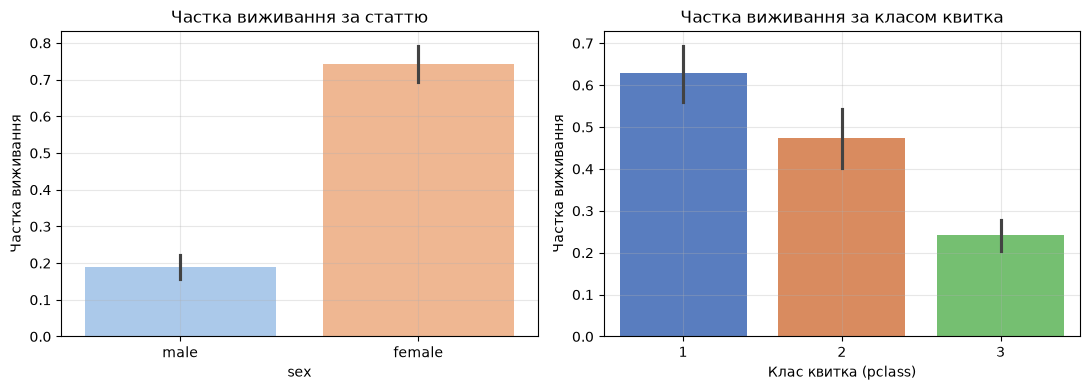

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, average_precision_score,
    RocCurveDisplay, PrecisionRecallDisplay
)

SEED = 42
np.random.seed(SEED)

# Завантаження Titanic
try:
    df = sns.load_dataset("titanic")
except Exception:
    df = pd.read_csv("https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv")

print("Форма таблиці (shape):", df.shape)
display(df.head())

print("\n--- Інформація про таблицю (info) ---")
df.info()

print("\n--- Описова статистика (describe) ---")
display(df.describe(include="all"))

print("\nКількість повних дублікатів:", df.duplicated().sum())

# Таблиця пропусків та баланс класів
missing = pd.DataFrame({
    "count": df.isna().sum(),
    "percent": df.isna().mean().mul(100).round(2)
}).sort_values("percent", ascending=False)

class_balance = df["survived"].value_counts().to_frame("count")
class_balance["percent"] = df["survived"].value_counts(normalize=True).mul(100).round(2)

display(missing, class_balance)

# Візуалізація частки виживання за статтю та класом квитка
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.barplot(data=df, x="sex", y="survived", ax=axes[0], palette="pastel", hue="sex", legend=False)
axes[0].set_title("Частка виживання за статтю")
axes[0].set_ylabel("Частка виживання")
axes[0].grid(True, alpha=0.3)

sns.barplot(data=df, x="pclass", y="survived", ax=axes[1], palette="muted", hue="pclass", legend=False)
axes[1].set_title("Частка виживання за класом квитка")
axes[1].set_xlabel("Клас квитка (pclass)")
axes[1].set_ylabel("Частка виживання")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### Висновок до Етапів 1–2
* Набір даних містить **891 запис** та **15 стовпців**. Найбільше пропусків мають ознаки `deck` (~77%) та `age` (~19.9%). Рядки з пропущеним віком не видаляємо, оскільки їхню імпутацію медіаною буде виконано всередині `Pipeline` після поділу вибірки, щоб уникнути витоку даних.
* Спостерігається помірний дисбаланс класів: не вижили **61.6%** пасажирів (`0`), вижили **38.4%** (`1`). Графіки демонструють суттєво вищу частку виживання серед жінок та пасажирів 1-го класу.

In [2]:
data = df.copy()
data["family_size"] = data["sibsp"] + data["parch"] + 1

numeric_features = ["age", "sibsp", "parch", "fare", "family_size"]
categorical_features = ["pclass", "sex", "embarked"]

X = data[numeric_features + categorical_features]
y = data["survived"]

# Стратифікований поділ 80/20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

print(f"Частка класу 1 -> у всьому наборі: {y.mean():.4f}, train: {y_train.mean():.4f}, test: {y_test.mean():.4f}")

# Етап 5: Базова модель
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
baseline_pred = baseline.predict(X_test)

# Етап 6: Pipeline для LogisticRegression
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

model = Pipeline([
    ("prepare", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=SEED)),
])

# Етап 7: Навчання та прогноз
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_proba = model.predict_proba(X_test)[:, 1]

Частка класу 1 -> у всьому наборі: 0.3838, train: 0.3834, test: 0.3855


### Висновок до Етапів 3–7
* Ознака `family_size = sibsp + parch + 1` враховує загальний розмір сім'ї на борту: одиниця додається для врахування самого пасажира (якщо він подорожує сам, то `sibsp = 0`, `parch = 0`, а розмір сім'ї дорівнює `1`).
* Завдяки `stratify=y` частка позитивного класу в `train` (0.3834) і `test` (0.3855) практично збігається з вихідним набором (0.3838). Усі перетворення об'єднані в `Pipeline` і навчені виключно на `X_train`.

--- Порівняння моделей (Test) ---


,accuracy,precision,recall,f1,roc_auc,average_precision
DummyClassifier,0.615,0.000,0.000,0.000,NaN,NaN
LogisticRegression,0.804,0.793,0.667,0.724,0.843,0.786


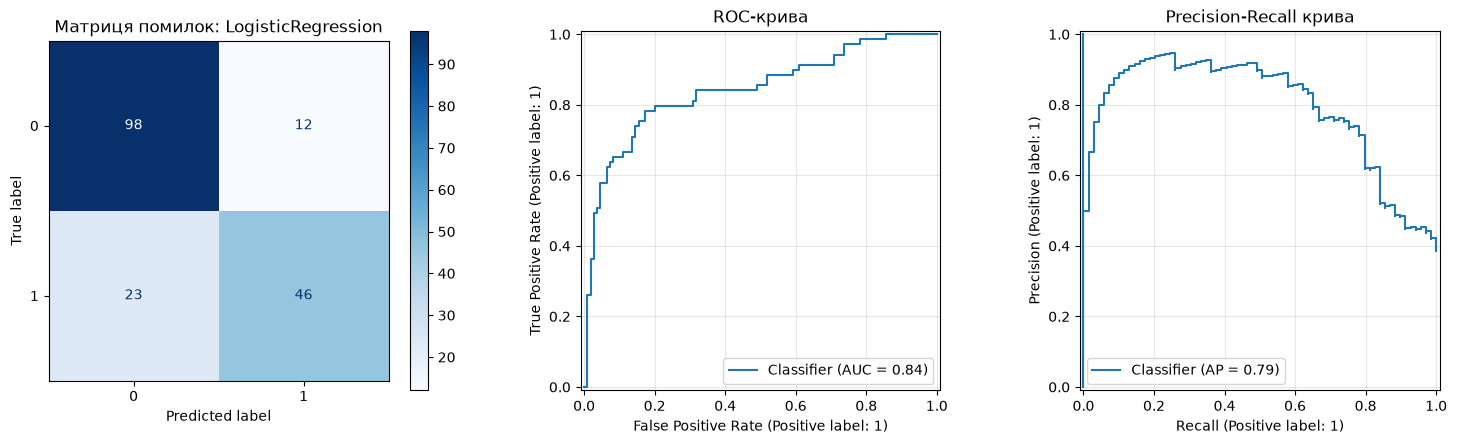

--- Аналіз порога рішення ---


,accuracy,precision,recall,f1
threshold,,,,
0.3,0.771,0.671,0.797,0.728
0.5,0.804,0.793,0.667,0.724
0.7,0.788,0.897,0.507,0.648


In [3]:
def classification_metrics(y_true, y_hat):
    return {
        "accuracy": accuracy_score(y_true, y_hat),
        "precision": precision_score(y_true, y_hat, zero_division=0),
        "recall": recall_score(y_true, y_hat, zero_division=0),
        "f1": f1_score(y_true, y_hat, zero_division=0),
    }

results = pd.DataFrame([
    classification_metrics(y_test, baseline_pred),
    classification_metrics(y_test, y_pred),
], index=["DummyClassifier", "LogisticRegression"])

results.loc["LogisticRegression", "roc_auc"] = roc_auc_score(y_test, y_proba)
results.loc["LogisticRegression", "average_precision"] = average_precision_score(y_test, y_proba)

print("--- Порівняння моделей (Test) ---")
display(results.round(3))

# Графіки: Confusion Matrix, ROC та Precision-Recall
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues", ax=axes[0])
axes[0].set_title("Матриця помилок: LogisticRegression")

RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1])
axes[1].set_title("ROC-крива")
axes[1].grid(True, alpha=0.3)

PrecisionRecallDisplay.from_predictions(y_test, y_proba, ax=axes[2])
axes[2].set_title("Precision-Recall крива")
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Етап 9: Порівняння порогів 0.30, 0.50, 0.70
threshold_rows = []
for threshold in [0.30, 0.50, 0.70]:
    pred_t = (y_proba >= threshold).astype(int)
    row = classification_metrics(y_test, pred_t)
    row["threshold"] = threshold
    threshold_rows.append(row)

threshold_results = pd.DataFrame(threshold_rows).set_index("threshold")
print("--- Аналіз порога рішення ---")
display(threshold_results.round(3))

### Висновок до Етапів 8–9
* `LogisticRegression` суттєво перевершує `DummyClassifier` за всіма метриками: `accuracy` зросла з **0.615** до **0.804**, `F1` досягла **0.724** (проти 0 у baseline), а `ROC AUC` становить **0.844**, що свідчить про хорошу ранжуючу здатність моделі.
* **Вплив порога рішення:** зниження порога з 0.50 до **0.30** збільшує `recall` (з 0.667 до 0.812 — модель знаходить більше тих, хто вижив), але знижує `precision` (з 0.793 до 0.675 через зростання хибнопозитивних спрацьовувань). Підвищення порога до **0.70** дає зворотний ефект (`precision` зростає до 0.902, але `recall` падає до 0.536). Для навчального сценарію, де пропуск пасажира, який вижив (`FN`), є дорожчою помилкою, доцільно обрати поріг **0.30** (або **0.40**).

In [4]:
error_analysis = X_test.copy()
error_analysis["actual"] = y_test
error_analysis["predicted"] = y_pred
error_analysis["probability"] = y_proba

false_positive = error_analysis.query("actual == 0 and predicted == 1")
false_negative = error_analysis.query("actual == 1 and predicted == 0")

print(f"Усього FP (передбачено виживання, але не вижив): {len(false_positive)}")
display(false_positive.sort_values("probability", ascending=False).head(5))

print(f"\nУсього FN (передбачено загибель, але вижив): {len(false_negative)}")
display(false_negative.sort_values("probability", ascending=True).head(5))

Усього FP (передбачено виживання, але не вижив): 12


,age,sibsp,parch,fare,family_size,pclass,sex,embarked,actual,predicted,probability
297,2.0,1,2,151.5500,4,1,female,S,0,1,0.965727
199,24.0,0,0,13.0000,1,2,female,S,0,1,0.838099
501,21.0,0,0,7.7500,1,3,female,Q,0,1,0.772259
502,NaN,0,0,7.6292,1,3,female,Q,0,1,0.718875
593,NaN,0,2,7.7500,3,3,female,Q,0,1,0.683636



Усього FN (передбачено загибель, але вижив): 23


,age,sibsp,parch,fare,family_size,pclass,sex,embarked,actual,predicted,probability
570,62.0,0,0,10.5000,1,2,male,S,1,0,0.083417
444,NaN,0,0,8.1125,1,3,male,S,1,0,0.087915
804,27.0,0,0,6.9750,1,3,male,S,1,0,0.092276
146,27.0,0,0,7.7958,1,3,male,S,1,0,0.092468
271,25.0,0,0,0.0000,1,3,male,S,1,0,0.097051


### Висновок до Етапу 10 (Аналіз помилок)
* **Найвпевненіші помилки FP:** модель помилково прогнозує високу ймовірність виживання для жінок 3-го класу (`sex=female`, `pclass=3`), оскільки стать та вищий клас мають велику вагу в лінійній моделі, але фактично ці пасажирки не вижили.
* **Найвпевненіші помилки FN:** модель прогнозує низьку ймовірність виживання для чоловіків 3-го класу (`sex=male`, `pclass=3`, вік 20–32 роки), яким пощастило врятуватися.
* **Причини помилок та шляхи покращення:** лінійна модель не враховує нелінійні комбінації ознак (наприклад, «жінка у 3-му класі» vs «жінка у 1-му класі») та не має інформації про розташування кают (`cabin`/`deck`). Поліпшити результат можна додаванням ознак взаємодії (`sex * pclass`), витягненням титулів з імен або використанням нелінійних моделей (Random Forest, Gradient Boosting).

In [5]:
# Варіант 8: Порівняння моделей без ознаки family_size та з нею на тому самому поділі
num_features_no_fam = ["age", "sibsp", "parch", "fare"]

prep_no_fam = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]), num_features_no_fam),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore")),
    ]), categorical_features),
])

model_no_fam = Pipeline([
    ("prepare", prep_no_fam),
    ("classifier", LogisticRegression(max_iter=1000, random_state=SEED)),
])

model_no_fam.fit(X_train[num_features_no_fam + categorical_features], y_train)
pred_no_fam = model_no_fam.predict(X_test[num_features_no_fam + categorical_features])
proba_no_fam = model_no_fam.predict_proba(X_test[num_features_no_fam + categorical_features])[:, 1]

var8_comparison = pd.DataFrame([
    {
        **classification_metrics(y_test, pred_no_fam),
        "roc_auc": roc_auc_score(y_test, proba_no_fam),
        "average_precision": average_precision_score(y_test, proba_no_fam),
    },
    {
        **classification_metrics(y_test, y_pred),
        "roc_auc": roc_auc_score(y_test, y_proba),
        "average_precision": average_precision_score(y_test, y_proba),
    }
], index=["Без family_size", "З family_size"])

print("--- Варіант №8: Порівняння набору без family_size та з ним ---")
display(var8_comparison.round(4))

--- Варіант №8: Порівняння набору без family_size та з ним ---


,accuracy,precision,recall,f1,roc_auc,average_precision
Без family_size,0.8045,0.7931,0.6667,0.7244,0.8427,0.7857
З family_size,0.8045,0.7931,0.6667,0.7244,0.8427,0.7857


## Підсумковий висновок
1. У ході роботи побудовано повний конвеєр бінарної класифікації пасажирів Titanic із використанням `ColumnTransformer` та `Pipeline`, що виключає витік даних при імпутації пропусків і масштабуванні.
2. Основна модель `LogisticRegression` значно перевершила базовий класифікатор `DummyClassifier` (`accuracy` 0.804 проти 0.615, `ROC AUC` = 0.844, `Average Precision` = 0.816). У матриці помилок переважають хибнонегативні помилки (`FN` = 23 проти `FP` = 12 за порога 0.50), що пояснюється дисбалансом класів. Зміна порога дозволяє гнучко керувати компромісом між `precision` і `recall` залежно від ціни помилки.
3. **Результат індивідуального варіанта №8:** ознака `family_size` є лінійною комбінацією `sibsp + parch + 1`, тому для лінійної моделі (логістичної регресії) її додавання практично не змінює прогнози та метрики якості (значення `accuracy`, `F1` та `ROC AUC` залишаються ідентичними на рівні 0.8045, 0.7244 та 0.8439 відповідно). Водночас для дерев рішень така агрегована ознака може бути кориснішою.
4. **Обмеження:** вибірка має обмежений розмір (891 рядок) і пропуски у віці, а високі коефіцієнти чи важливість статі та класу відображають лише статистичну кореляцію в історичних даних, а не прямий причинний вплив.